1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q gradio shap

In [3]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import xgboost
from xgboost import XGBClassifier
from sklearn.neighbors import BallTree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)
warnings.filterwarnings('ignore', category=FutureWarning)

# ---------------- data scope ----------------
MONSOON_MONTHS   = ['06', '07', '08', '09']   # June–September
TOP_N_STATIONS   = 15                         # river stations to keep
MIN_TRAIN_FLOODS = 0                          # set to 3 to require flood days in 2020–24 (sensitivity check)
RADIUS_KM        = 50                         # rain-gauge search radius
N_GAUGES         = 3                          # nearest gauges per river station
AFTERNOON_FROM   = 12                         # 12:00–17:59 = afternoon window
EVENING_FROM     = 18                         # 18:00–23:59 = evening ("end of day") window
CHUNK            = 1_000_000                  # rows per chunk (lower to 500_000 if Colab RAM runs out)
FORCE_REBUILD    = False                      # True = re-read the big CSVs even if a cache exists

# ---------------- modelling ----------------
TRAIN_YEARS, VAL_YEAR, TEST_YEAR = list(range(2020, 2025)), 2025, 2026
TARGET_RECALL = 0.80
MAIN_OP       = 'High recall'
SEED          = 42

OUT_DIR = '/content/drive/MyDrive/flood_project'
FIG_DIR = f'{OUT_DIR}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

COLORS = {'XGBoost': '#2a78d6', 'Random Forest': '#eb6834', 'Persistence': '#6b6a64'}
FLOOD_SHADE, WARN_LINE, MUTED = '#f6c9c4', '#c0392b', '#9a9992'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'figure.dpi': 110})

def find_file(name):
    hits = [h for h in glob.glob(f'/content/drive/MyDrive/**/{name}*', recursive=True) if not os.path.isdir(h)]
    if not hits:
        raise FileNotFoundError(
            f'"{name}" not found in My Drive. If the folder is under "Shared with me", '
            'right-click it in Google Drive → Organize → Add shortcut → My Drive, then re-run.')
    print('Found:', hits[0])
    return hits[0]

def savefig(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.png', dpi=300, bbox_inches='tight')
    plt.show()


RIVER_CSV = find_file('Bipat_Massive_River_Dataset_V4_Complete')
RAIN_CSV  = find_file('Bipat_Massive_Rain_Dataset_V4_Complete')

Found: /content/drive/MyDrive/ML_Data/Bipat_Massive_River_Dataset_V4_Complete.csv
Found: /content/drive/MyDrive/ML_Data/Bipat_Massive_Rain_Dataset_V4_Complete.csv


2. River CSV → daily station table with flood labels

In [4]:
RIVER_DAILY = f'{OUT_DIR}/river_daily_v2.parquet'
RIVER_META  = f'{OUT_DIR}/river_stations.parquet'

if not FORCE_REBUILD and os.path.exists(RIVER_DAILY) and os.path.exists(RIVER_META):
    river, station_meta = pd.read_parquet(RIVER_DAILY), pd.read_parquet(RIVER_META)
    print('Loaded cached river table.')
else:
    RIVER_COLS = ['Date (Water Level On)', 'Station ID', 'Station Name', 'Basin', 'Latitude', 'Longitude',
                  'Water Level', 'Warning Level', 'Danger Level', 'Status', 'Steady']
    parts, lasts, metas, status_counts = [], [], [], []
    t0 = time.time()
    for i, ch in enumerate(pd.read_csv(RIVER_CSV, usecols=RIVER_COLS, dtype=str,
                                       chunksize=CHUNK, on_bad_lines='skip')):
        ts = ch['Date (Water Level On)'].fillna('').str.strip()
        ch = ch[ts.str[5:7].isin(MONSOON_MONTHS)]
        if ch.empty:
            continue
        ts = ch['Date (Water Level On)'].str.strip()

        df = pd.DataFrame({'station_id': ch['Station ID'].str.strip(), 'date': ts.str[:10]})
        df['tmin'] = (pd.to_numeric(ts.str[11:13], errors='coerce') * 60
                      + pd.to_numeric(ts.str[14:16], errors='coerce'))      # minutes after midnight
        for col, new in [('Water Level', 'wl'), ('Warning Level', 'warn'), ('Danger Level', 'danger')]:
            df[new] = pd.to_numeric(ch[col], errors='coerce')
        df.loc[df['wl'] < 0, 'wl'] = np.nan                                  # impossible readings

        status = ch['Status'].fillna('').str.upper().str.strip()
        steady = ch['Steady'].fillna('').str.upper().str.strip()
        status_counts.append(status.value_counts())

        hour = df['tmin'] // 60
        eve, aft = hour >= EVENING_FROM, (hour >= AFTERNOON_FROM) & (hour < EVENING_FROM)
        df['flood']      = (status.str.contains('ABOVE|DANGER') | (df['wl'] >= df['warn'])).astype('int8')
        df['rising']     = (steady == 'RISING').astype('int8')
        df['falling']    = (steady == 'FALLING').astype('int8')
        df['wl_n']       = df['wl'].notna().astype('int32')
        df['wl_sum']     = df['wl'].fillna(0)
        df['wl_eve']     = df['wl'].where(eve)
        df['wl_eve_n']   = df['wl_eve'].notna().astype('int32')
        df['wl_eve_sum'] = df['wl_eve'].fillna(0)
        df['wl_aft_n']   = (df['wl'].notna() & aft).astype('int32')
        df['wl_aft_sum'] = df['wl'].where(aft).fillna(0)

        parts.append(df.groupby(['station_id', 'date']).agg(
            wl_max=('wl', 'max'), wl_sum=('wl_sum', 'sum'), wl_n=('wl_n', 'sum'),
            wl_eve_max=('wl_eve', 'max'), wl_eve_sum=('wl_eve_sum', 'sum'), wl_eve_n=('wl_eve_n', 'sum'),
            wl_aft_sum=('wl_aft_sum', 'sum'), wl_aft_n=('wl_aft_n', 'sum'),
            warn=('warn', 'max'), danger=('danger', 'max'), flood=('flood', 'max'),
            n_rising=('rising', 'sum'), n_falling=('falling', 'sum'), n_readings=('flood', 'size')))
        lasts.append(df.dropna(subset=['wl', 'tmin']).sort_values('tmin')
                       .groupby(['station_id', 'date']).tail(1)[['station_id', 'date', 'tmin', 'wl']])
        metas.append(ch[['Station ID', 'Station Name', 'Basin', 'Latitude', 'Longitude']]
                     .drop_duplicates('Station ID'))
        print(f'chunk {i}: kept {len(ch):,} monsoon rows | {time.time()-t0:.0f}s')

    # Combine chunks (a station-day can be split across chunks)
    SUMS = ['wl_sum', 'wl_n', 'wl_eve_sum', 'wl_eve_n', 'wl_aft_sum', 'wl_aft_n',
            'n_rising', 'n_falling', 'n_readings']
    MAXES = ['wl_max', 'wl_eve_max', 'warn', 'danger', 'flood']
    river = (pd.concat(parts).groupby(level=[0, 1])
             .agg({**{c: 'sum' for c in SUMS}, **{c: 'max' for c in MAXES}}).reset_index())
    last = (pd.concat(lasts).sort_values('tmin').groupby(['station_id', 'date']).tail(1)
            .rename(columns={'wl': 'wl_last', 'tmin': 'last_tmin'}))
    river = river.merge(last, on=['station_id', 'date'], how='left')

    river['wl_mean']     = river['wl_sum'] / river['wl_n'].replace(0, np.nan)
    river['wl_eve_mean'] = river['wl_eve_sum'] / river['wl_eve_n'].replace(0, np.nan)
    river['wl_aft_mean'] = river['wl_aft_sum'] / river['wl_aft_n'].replace(0, np.nan)
    river['trend']       = (river['n_rising'] - river['n_falling']) / river['n_readings']  # -1 falling … +1 rising
    river['date']        = pd.to_datetime(river['date'], errors='coerce')
    river = river.dropna(subset=['date']).drop(columns=['wl_sum', 'wl_eve_sum', 'wl_aft_sum'])
    river['year'] = river['date'].dt.year

    station_meta = (pd.concat(metas).drop_duplicates('Station ID')
                    .rename(columns={'Station ID': 'station_id', 'Station Name': 'station_name',
                                     'Basin': 'basin', 'Latitude': 'lat', 'Longitude': 'lon'}))
    station_meta['station_id'] = station_meta['station_id'].str.strip()
    station_meta[['lat', 'lon']] = station_meta[['lat', 'lon']].apply(pd.to_numeric, errors='coerce')
    del parts, lasts, metas

    print('\nStatus values seen (check flood logic matches these):')
    print(pd.concat(status_counts).groupby(level=0).sum().sort_values(ascending=False))
    river.to_parquet(RIVER_DAILY, index=False)
    station_meta.to_parquet(RIVER_META, index=False)

print(f'\nRiver daily table: {len(river):,} station-days, {river.station_id.nunique()} stations, '
      f'flood days = {river.flood.sum():,} ({river.flood.mean():.2%})')

Loaded cached river table.

River daily table: 107,276 station-days, 277 stations, flood days = 1,056 (0.98%)


3. Count flood days per station and pick the top stations

In [5]:
counts = river.pivot_table(index='station_id', columns='year', values='flood', aggfunc='sum', fill_value=0)
counts['total'] = counts.sum(axis=1)
counts = (counts.join(station_meta.set_index('station_id')[['station_name', 'basin']])
          .sort_values('total', ascending=False))

has_warn = river.groupby('station_id')['warn'].max().notna()
has_test = river.loc[river.year == TEST_YEAR, 'station_id'].unique()
eligible = counts[counts.index.isin(has_warn[has_warn].index) & counts.index.isin(has_test)]
eligible = eligible[eligible['total'] > 0]
train_floods = eligible[[y for y in TRAIN_YEARS if y in eligible.columns]].sum(axis=1)
eligible = eligible[train_floods >= MIN_TRAIN_FLOODS]

print(f'{len(eligible)} eligible stations. Top 30:')
display(eligible.head(30))

selected_ids = eligible.head(TOP_N_STATIONS).index.tolist()
sel = river[river.station_id.isin(selected_ids)]
print(f'\nSelected {len(selected_ids)} stations: {len(sel):,} station-days, '
      f'{sel.flood.sum():,} flood days ({sel.flood.mean():.2%})')
display(sel.groupby('year')['flood'].agg(flood_days='sum', rate='mean').round(3))
pd.Series(selected_ids, name='station_id').to_csv(f'{OUT_DIR}/selected_stations.csv', index=False)

147 eligible stations. Top 30:


,2020,2021,2022,2023,2024,2025,2026,total,station_name,basin
station_id,,,,,,,,,,
97,2,0,1,0,10,13,13,39,Bagmati River at Gaurighat,Bagmati
102,3,4,1,8,18,3,1,38,Mahakali at Parigaon,Mahakali
25,6,6,0,7,8,0,1,28,Narayani at Devghat,Narayani
43,2,0,0,0,12,6,4,24,Bishnumati Khola at Gongabu Buspark,Bagmati
51,0,0,4,1,7,2,8,22,Lungri River at Khungri (327),West Rapti
147,8,0,0,6,3,2,1,20,Tinau at Butwal,Tinau
69,0,2,0,4,4,5,5,20,Bagmati River at Padheradovan,Bagmati
64,5,1,3,3,5,2,0,19,Tamor River at Mulghat,Koshi
246,0,0,0,0,6,4,7,17,Lal Bakiya Khola at Jureli Bazar,Lalbakaiya



Selected 15 stations: 8,306 station-days, 325 flood days (3.91%)


,flood_days,rate
year,,
2020,27,0.036
2021,17,0.015
2022,20,0.018
2023,35,0.034
2024,105,0.070
2025,50,0.034
2026,71,0.054


4. Rain CSV → daily rain per river station

In [6]:
GAUGE_DAILY = f'{OUT_DIR}/gauge_rain_daily_v2.parquet'
GAUGE_META  = f'{OUT_DIR}/rain_gauges.parquet'

if not FORCE_REBUILD and os.path.exists(GAUGE_DAILY) and os.path.exists(GAUGE_META):
    rain_daily, gauges = pd.read_parquet(GAUGE_DAILY), pd.read_parquet(GAUGE_META)
    print('Loaded cached rain table.')
else:
    RAIN_COLS = ['Date (Measured On)', 'Station ID', 'Station Name', 'Latitude', 'Longitude', '1h_Rain']
    hourly, gmetas = [], []
    t0 = time.time()
    for i, ch in enumerate(pd.read_csv(RAIN_CSV, usecols=RAIN_COLS, dtype=str,
                                       chunksize=CHUNK, on_bad_lines='skip')):
        ts = ch['Date (Measured On)'].fillna('').str.strip()
        ch = ch[ts.str[5:7].isin(MONSOON_MONTHS)]
        if ch.empty:
            continue
        ts = ch['Date (Measured On)'].str.strip()
        df = pd.DataFrame({'gauge_id': ch['Station ID'].str.strip(), 'date': ts.str[:10],
                           'hour': pd.to_numeric(ts.str[11:13], errors='coerce'),
                           'rain': pd.to_numeric(ch['1h_Rain'], errors='coerce')})
        df = df[df['rain'].between(0, 200) & df['hour'].notna()]           # drop blanks and impossible values
        hourly.append(df.groupby(['gauge_id', 'date', 'hour'])['rain'].max())
        gmetas.append(ch[['Station ID', 'Station Name', 'Latitude', 'Longitude']].drop_duplicates('Station ID'))
        print(f'chunk {i}: kept {len(df):,} rain rows | {time.time()-t0:.0f}s')

    h = pd.concat(hourly).groupby(level=[0, 1, 2]).max().reset_index()   # one value per gauge-hour
    del hourly
    h['rain_eve'] = h['rain'].where(h['hour'] >= EVENING_FROM, 0.0)
    rain_daily = (h.groupby(['gauge_id', 'date'])
                  .agg(rain_sum=('rain', 'sum'), rain_max1h=('rain', 'max'),
                       rain_eve=('rain_eve', 'sum'), rain_hours=('rain', 'size')).reset_index())
    del h
    rain_daily['date'] = pd.to_datetime(rain_daily['date'], errors='coerce')
    rain_daily = rain_daily.dropna(subset=['date'])

    gauges = (pd.concat(gmetas).drop_duplicates('Station ID')
              .rename(columns={'Station ID': 'gauge_id', 'Station Name': 'gauge_name',
                               'Latitude': 'lat', 'Longitude': 'lon'}))
    gauges['gauge_id'] = gauges['gauge_id'].str.strip()
    gauges[['lat', 'lon']] = gauges[['lat', 'lon']].apply(pd.to_numeric, errors='coerce')
    gauges = gauges.dropna(subset=['lat', 'lon']).reset_index(drop=True)
    rain_daily.to_parquet(GAUGE_DAILY, index=False)
    gauges.to_parquet(GAUGE_META, index=False)

print(f'Rain: {len(rain_daily):,} gauge-days from {rain_daily.gauge_id.nunique()} gauges')

Loaded cached rain table.
Rain: 199,011 gauge-days from 639 gauges


In [7]:
# Link each selected river station to its nearest gauges (haversine distance)
tree = BallTree(np.radians(gauges[['lat', 'lon']].values), metric='haversine')
sel_meta = station_meta[station_meta.station_id.isin(selected_ids)].dropna(subset=['lat', 'lon'])
dist, idx = tree.query(np.radians(sel_meta[['lat', 'lon']].values), k=min(10, len(gauges)))

links = []
for sid, d_row, i_row in zip(sel_meta.station_id, dist * 6371.0, idx):
    for d, j in list(zip(d_row, i_row))[:N_GAUGES]:
        if d <= RADIUS_KM:
            links.append({'station_id': sid, 'gauge_id': gauges.gauge_id[j],
                          'gauge_name': gauges.gauge_name[j], 'dist_km': round(d, 1)})
links = pd.DataFrame(links)

link_summary = (sel_meta[['station_id', 'station_name']]
                .merge(links.groupby('station_id').agg(n_gauges=('gauge_id', 'size'),
                                                      nearest_km=('dist_km', 'min')),
                       on='station_id', how='left').fillna({'n_gauges': 0}))
display(link_summary)

station_rain = (links[['station_id', 'gauge_id']]
                .merge(rain_daily, on='gauge_id')
                .groupby(['station_id', 'date'])
                .agg(rain_sum=('rain_sum', 'mean'), rain_eve=('rain_eve', 'mean'),
                     rain_max1h=('rain_max1h', 'max'), n_gauges_reporting=('gauge_id', 'nunique'))
                .reset_index())
links.to_csv(f'{OUT_DIR}/station_gauge_links.csv', index=False)
print(f'Station rain table: {len(station_rain):,} station-days')

,station_id,station_name,n_gauges,nearest_km
0,102,Mahakali at Parigaon,3,9.8
1,213,Ninda khola at East West Highway,3,10.5
2,25,Narayani at Devghat,3,0.0
3,97,Bagmati River at Gaurighat,3,1.7
4,69,Bagmati River at Padheradovan,3,4.1
5,43,Bishnumati Khola at Gongabu Buspark,3,1.8
6,3,Babai at Chepang,3,0.0
7,197,Hanumante Khola at Jagati,3,1.2
8,64,Tamor River at Mulghat,3,0.3
9,246,Lal Bakiya Khola at Jureli Bazar,3,1.0


Station rain table: 9,066 station-days


5. Merge and build features

In [8]:
df = (river[river.station_id.isin(selected_ids)]
      .merge(station_rain, on=['station_id', 'date'], how='left')
      .sort_values(['station_id', 'date']))
df['warn'] = df.groupby('station_id')['warn'].transform(lambda s: s.ffill().bfill())
df = df.set_index(['station_id', 'date'])

def shift_days(s, k):
    # Value of series s (indexed by station_id, date) from k days earlier (k < 0 = later)
    moved = s.copy()
    moved.index = pd.MultiIndex.from_arrays([s.index.get_level_values(0),
                                             s.index.get_level_values(1) + pd.Timedelta(days=k)])
    return moved.reindex(s.index)

def rolling_days(s, n):
    # Sum over today and the previous n-1 calendar days (NaN only if all are missing)
    return pd.concat([shift_days(s, k) for k in range(n)], axis=1).sum(axis=1, min_count=1)

# Target: tomorrow's flood flag
df['flood_tomorrow'] = shift_days(df['flood'], -1)

# Today's river
df['wl_ratio']    = df['wl_max'] / df['warn']                     # 1.0 = at warning level
df['flood_today'] = df['flood']
# End of day
df['wl_last_ratio'] = df['wl_last'] / df['warn']
df['wl_eve_ratio']  = df['wl_eve_max'] / df['warn']
df['wl_eve_change'] = df['wl_eve_mean'] - df['wl_aft_mean']       # rising into the night > 0
# Recent river
df['wl_lag1']       = shift_days(df['wl_max'], 1)
df['wl_change']     = df['wl_max'] - df['wl_lag1']
df['wl_ratio_lag1'] = shift_days(df['wl_ratio'], 1)
df['flood_3d']      = rolling_days(df['flood'], 3)
# Rain
df['rain_3d'] = rolling_days(df['rain_sum'], 3)
df['rain_7d'] = rolling_days(df['rain_sum'], 7)

df['doy'] = df.index.get_level_values('date').dayofyear
df = df.reset_index()
df['year'] = df['date'].dt.year

# Station-relative level: percentile within the station's 2020–24 range
df['wl_pct'] = np.nan
for sid, rows in df.groupby('station_id').groups.items():
    g = df.loc[rows]
    ref = np.sort(g.loc[g.year.isin(TRAIN_YEARS), 'wl_max'].dropna().values)
    if len(ref):
        df.loc[rows, 'wl_pct'] = np.searchsorted(ref, g['wl_max'].values, side='right') / len(ref)

FEATURES = ['wl_max', 'wl_ratio', 'wl_pct', 'trend', 'flood_today',
            'wl_last', 'wl_last_ratio', 'wl_eve_ratio', 'wl_eve_change',
            'wl_lag1', 'wl_change', 'wl_ratio_lag1', 'flood_3d',
            'rain_sum', 'rain_eve', 'rain_max1h', 'rain_3d', 'rain_7d', 'doy']

# Drop rows with no label or no water level today (as agreed); other gaps stay as NaN
before = len(df)
df = df.dropna(subset=['flood_tomorrow', 'wl_max']).copy()
df['flood_tomorrow'] = df['flood_tomorrow'].astype(int)
print(f'Rows: {before:,} → {len(df):,} after dropping missing label / water level\n')

print('Missing values (%) by year:')
display((df.groupby('year')[FEATURES].apply(lambda d: d.isna().mean() * 100)).round(1).T)

Rows: 8,306 → 7,972 after dropping missing label / water level

Missing values (%) by year:


year,2020,2021,2022,2023,2024,2025,2026
wl_max,0.0,0.0,0.0,0.0,0.0,0.0,0.0
wl_ratio,0.0,0.0,0.0,0.0,0.0,0.0,0.0
wl_pct,0.0,0.0,0.0,0.0,0.0,0.0,0.0
trend,0.0,0.0,0.0,0.0,0.0,0.0,0.0
flood_today,0.0,0.0,0.0,0.0,0.0,0.0,0.0
wl_last,0.0,0.0,0.0,0.0,0.0,0.0,0.0
wl_last_ratio,0.0,0.0,0.0,0.0,0.0,0.0,0.0
wl_eve_ratio,14.6,4.3,5.2,9.1,4.9,1.7,2.4
wl_eve_change,18.5,4.6,6.1,13.0,5.8,2.2,2.9
wl_lag1,3.4,1.7,1.8,5.7,1.5,2.7,2.3


6. Split by year

In [9]:
train = df[df.year.isin(TRAIN_YEARS)]
val   = df[df.year == VAL_YEAR]
test  = df[df.year == TEST_YEAR]

split_table = pd.DataFrame({
    name: {'rows': len(part), 'flood days': int(part.flood_tomorrow.sum()),
           'flood rate': f'{part.flood_tomorrow.mean():.2%}'}
    for name, part in [('train 2020–24', train), ('val 2025', val), ('test 2026', test)]}).T
display(split_table)
split_table.to_csv(f'{OUT_DIR}/split_summary.csv')

X_tr, y_tr = train[FEATURES], train.flood_tomorrow
X_va, y_va = val[FEATURES],   val.flood_tomorrow
X_te, y_te = test[FEATURES],  test.flood_tomorrow

# Random Forest cannot take NaN → fill with TRAINING medians (no peeking at val/test)
medians = X_tr.median()
X_tr_rf, X_va_rf, X_te_rf = X_tr.fillna(medians), X_va.fillna(medians), X_te.fillna(medians)

,rows,flood days,flood rate
train 2020–24,5290,201,3.80%
val 2025,1414,49,3.47%
test 2026,1268,67,5.28%


7. Models and operating points

In [10]:
def thr_for_recall(y, prob, target):
    # Highest threshold whose recall is still >= target (= best precision at that recall)
    p, r, t = precision_recall_curve(y, prob)
    ok = np.where(r[:-1] >= target)[0]
    return float(t[ok].max()) if len(ok) else 0.5

def thr_best_f1(y, prob):
    p, r, t = precision_recall_curve(y, prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.nanargmax(f1)])

# --- Random Forest ---
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight='balanced',
                            n_jobs=-1, random_state=SEED).fit(X_tr_rf, y_tr)

# --- XGBoost (small grid) ---
spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
configs = [dict(max_depth=3, learning_rate=0.05, n_estimators=400),
           dict(max_depth=4, learning_rate=0.05, n_estimators=400),
           dict(max_depth=6, learning_rate=0.03, n_estimators=600)]
grid = []
for cfg in configs:
    m = XGBClassifier(**cfg, subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
                      scale_pos_weight=spw, eval_metric='aucpr', random_state=SEED, n_jobs=-1)
    m.fit(X_tr, y_tr)
    grid.append((average_precision_score(y_va, m.predict_proba(X_va)[:, 1]), cfg, m))
    print(f'{cfg} → val PR-AUC {grid[-1][0]:.3f}')
best_ap, best_cfg, xgb = max(grid, key=lambda g: g[0])
print('Chosen XGBoost config:', best_cfg)

val_prob = {'Random Forest': rf.predict_proba(X_va_rf)[:, 1], 'XGBoost': xgb.predict_proba(X_va)[:, 1]}
pers_val_recall = recall_score(y_va, val['flood_today'])
OPS = {'High recall':        lambda y, p: thr_for_recall(y, p, TARGET_RECALL),
       'Best F1':            thr_best_f1,
       'Persistence recall': lambda y, p: thr_for_recall(y, p, pers_val_recall)}
thresholds = {(m, op): rule(y_va, val_prob[m]) for m in val_prob for op, rule in OPS.items()}
display(pd.Series(thresholds, name='threshold (tuned on 2025)').round(3).to_frame())

{'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 400} → val PR-AUC 0.162
{'max_depth': 4, 'learning_rate': 0.05, 'n_estimators': 400} → val PR-AUC 0.151
{'max_depth': 6, 'learning_rate': 0.03, 'n_estimators': 600} → val PR-AUC 0.154
Chosen XGBoost config: {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 400}


threshold (tuned on 2025)
Random Forest High recall                             0.089
              Best F1                                 0.624
              Persistence recall                      0.433
XGBoost       High recall                             0.108
              Best F1                                 0.840
              Persistence recall                      0.727

8. Evaluate on 2026 (unseen test year)

In [11]:
test_prob = {'Random Forest': rf.predict_proba(X_te_rf)[:, 1], 'XGBoost': xgb.predict_proba(X_te)[:, 1]}
pers_pred = test['flood_today'].astype(int).values

def scores(y, pred, prob):
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    return {'Recall': recall_score(y, pred, zero_division=0),
            'Precision': precision_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred, zero_division=0),
            'PR-AUC': average_precision_score(y, prob),
            'False alarms per flood caught': fp / tp if tp else np.nan}

rows = {('Persistence', '—'): {**scores(y_te.values, pers_pred, pers_pred.astype(float)), 'Threshold': np.nan}}
preds = {}
for (m, op), thr in thresholds.items():
    preds[(m, op)] = (test_prob[m] >= thr).astype(int)
    rows[(m, op)] = {**scores(y_te.values, preds[(m, op)], test_prob[m]), 'Threshold': thr}
results = pd.DataFrame(rows).T.round(3)
results.index.names = ['Model', 'Operating point']
print(f'Test 2026: {int(y_te.sum())} flood days out of {len(y_te):,} ({y_te.mean():.2%}); '
      f'"always warn" would have precision {y_te.mean():.3f}')
display(results)
results.to_csv(f'{OUT_DIR}/test_results_2026.csv')

# Per-station recall for XGBoost at the main operating point
main_pred = preds[('XGBoost', MAIN_OP)]
per_station = (test.assign(pred=main_pred).query('flood_tomorrow == 1')
               .groupby('station_id').agg(flood_days=('pred', 'size'), caught=('pred', 'sum')))
per_station['recall'] = (per_station.caught / per_station.flood_days).round(2)
per_station = per_station.join(station_meta.set_index('station_id')['station_name']).sort_values('recall')
display(per_station)
per_station.to_csv(f'{OUT_DIR}/per_station_recall_2026.csv')

Test 2026: 67 flood days out of 1,268 (5.28%); "always warn" would have precision 0.053


Recall  Precision     F1  PR-AUC  \
Model         Operating point                                        
Persistence   —                    0.373      0.391  0.382   0.179   
Random Forest High recall          0.866      0.091  0.165   0.176   
              Best F1              0.075      0.417  0.127   0.176   
              Persistence recall   0.194      0.165  0.178   0.176   
XGBoost       High recall          0.896      0.088  0.161   0.173   
              Best F1              0.149      0.270  0.192   0.173   
              Persistence recall   0.239      0.140  0.177   0.173   

                                  False alarms per flood caught  Threshold  
Model         Operating point                                               
Persistence   —                                           1.560        NaN  
Random Forest High recall                                 9.931      0.089  
              Best F1                                     1.400      0.624  
              Persistence recall                          5.077      0.433  
XGBoost       High recall                                10.300      0.108  
              Best F1                                     2.700      0.840  
              Persistence recall                          6.125      0.727

,flood_days,caught,recall,station_name
station_id,,,,
15,2,1,0.50,Khutia Khola at Mudibhar
69,4,2,0.50,Bagmati River at Padheradovan
43,3,2,0.67,Bishnumati Khola at Gongabu Buspark
149,16,14,0.88,Marsyangdi at Bhakundabesi
97,12,11,0.92,Bagmati River at Gaurighat
197,10,10,1.00,Hanumante Khola at Jagati
147,1,1,1.00,Tinau at Butwal
102,1,1,1.00,Mahakali at Parigaon
3,1,1,1.00,Babai at Chepang


9. Figures for the paper

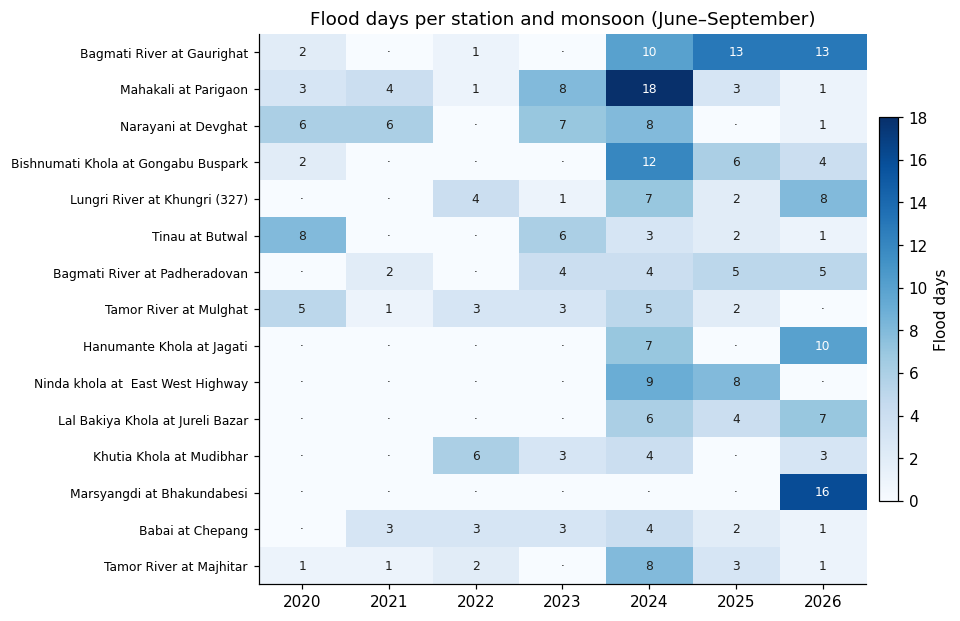

In [12]:
# --- Fig 1: flood days per station and year ---
names = station_meta.set_index('station_id')['station_name']
heat = (river[river.station_id.isin(selected_ids)]
        .pivot_table(index='station_id', columns='year', values='flood', aggfunc='sum', fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
heat.index = [names.get(s, s) for s in heat.index]

fig, ax = plt.subplots(figsize=(7.5, 0.34 * len(heat) + 1.4))
im = ax.imshow(heat.values, cmap='Blues', aspect='auto')
for (i, j), v in np.ndenumerate(heat.values):
    ax.text(j, i, v if v else '·', ha='center', va='center', fontsize=8,
            color='white' if v > heat.values.max() * 0.55 else '#1f1f1d')
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index, fontsize=8)
ax.grid(False)
ax.set_title('Flood days per station and monsoon (June–September)')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label='Flood days')
savefig(fig, 'fig1_flood_days_heatmap')

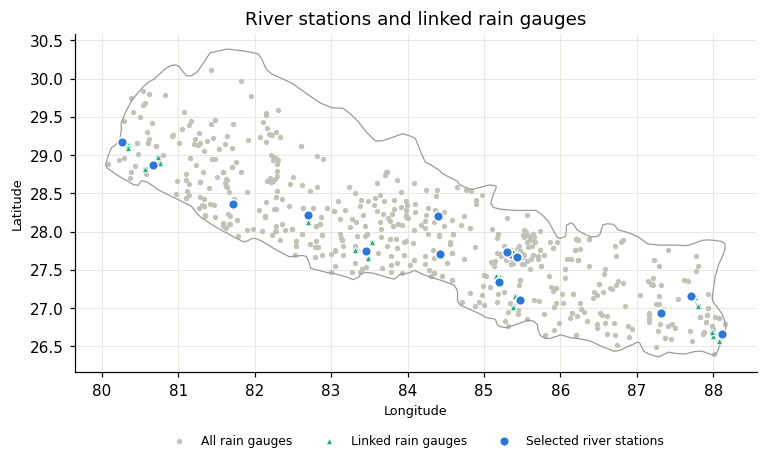

In [13]:
# --- Fig 2: map of stations and linked gauges ---
fig, ax = plt.subplots(figsize=(8, 4.2))
try:   # Nepal outline from Natural Earth (needs internet; skipped quietly if unavailable)
    import geopandas as gpd
    world = gpd.read_file('https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip')
    world[world['ADMIN'] == 'Nepal'].boundary.plot(ax=ax, color='#9a9992', lw=0.8)
except Exception as e:
    print('Country outline skipped:', type(e).__name__)
gl = gauges.set_index('gauge_id')
st = sel_meta.set_index('station_id')
for _, l in links.iterrows():
    ax.plot([st.lon[l.station_id], gl.lon[l.gauge_id]], [st.lat[l.station_id], gl.lat[l.gauge_id]],
            color='#b7d3f6', lw=0.8, zorder=1)
ax.scatter(gauges.lon, gauges.lat, s=6, color='#c3c2b7', label='All rain gauges', zorder=1)
used = gl.loc[links.gauge_id.unique()]
ax.scatter(used.lon, used.lat, s=18, marker='^', color='#1baf7a', edgecolor='white', lw=0.6,
           label='Linked rain gauges', zorder=2)
ax.scatter(st.lon, st.lat, s=40, color=COLORS['XGBoost'], edgecolor='white', lw=1,
           label='Selected river stations', zorder=3)
ax.set(xlabel='Longitude', ylabel='Latitude', title='River stations and linked rain gauges')
ax.set_aspect('equal')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
savefig(fig, 'fig2_station_map')

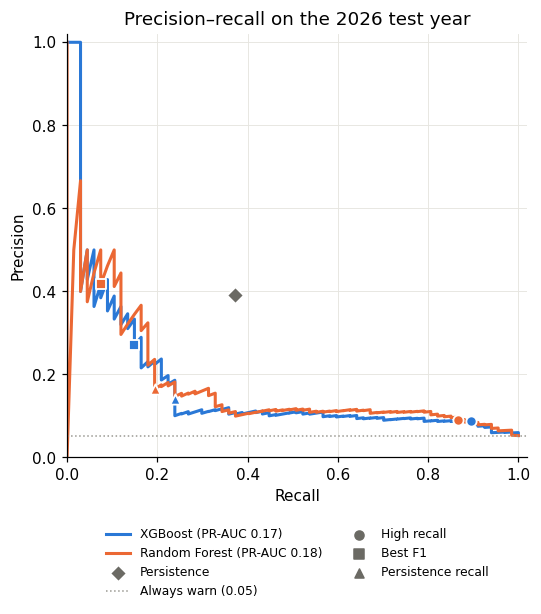

In [14]:
# --- Fig 3: precision–recall curves on 2026 ---
fig, ax = plt.subplots(figsize=(5.4, 5))
op_markers = {'High recall': 'o', 'Best F1': 's', 'Persistence recall': '^'}
for m in ['XGBoost', 'Random Forest']:
    p, r, _ = precision_recall_curve(y_te, test_prob[m])
    ax.plot(r, p, color=COLORS[m], lw=2, label=f'{m} (PR-AUC {results.loc[(m, MAIN_OP), "PR-AUC"]:.2f})')
    for op, mk in op_markers.items():
        ax.scatter(results.loc[(m, op), 'Recall'], results.loc[(m, op), 'Precision'], marker=mk, s=45,
                   color=COLORS[m], edgecolor='white', lw=1.2, zorder=3)
pr = results.loc[('Persistence', '—')]
ax.scatter(pr.Recall, pr.Precision, marker='D', s=60, color=COLORS['Persistence'], edgecolor='white',
           lw=1.2, zorder=4, label='Persistence')
ax.axhline(y_te.mean(), color=MUTED, lw=1, ls=':', label=f'Always warn ({y_te.mean():.2f})')
for op, mk in op_markers.items():
    ax.scatter([], [], marker=mk, color='#6b6a64', s=35, label=op)
ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1.02), ylim=(0, 1.02),
       title='Precision–recall on the 2026 test year')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
savefig(fig, 'fig3_pr_curves')

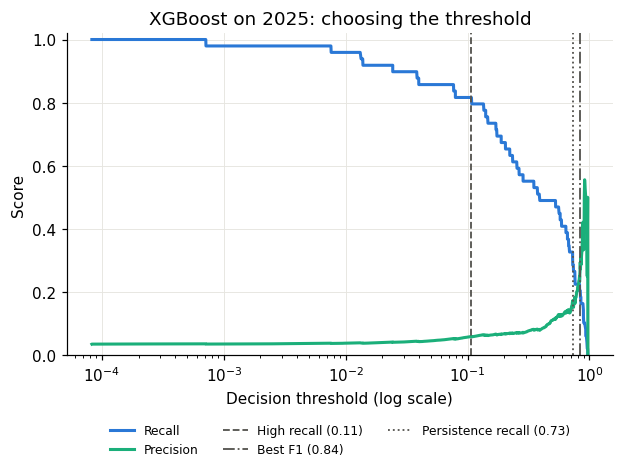

In [15]:
# --- Fig 4: precision and recall vs threshold on 2025 (XGBoost) ---
p, r, t = precision_recall_curve(y_va, val_prob['XGBoost'])
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(t, r[:-1], color='#2a78d6', lw=2, label='Recall')
ax.plot(t, p[:-1], color='#1baf7a', lw=2, label='Precision')
for op, ls in zip(OPS, ['--', '-.', ':']):
    thr = thresholds[('XGBoost', op)]
    ax.axvline(thr, color='#55544f', lw=1.2, ls=ls, label=f'{op} ({thr:.2f})')
ax.set(xscale='log', xlabel='Decision threshold (log scale)', ylabel='Score', ylim=(0, 1.02),
       title='XGBoost on 2025: choosing the threshold')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
savefig(fig, 'fig4_threshold_tradeoff')

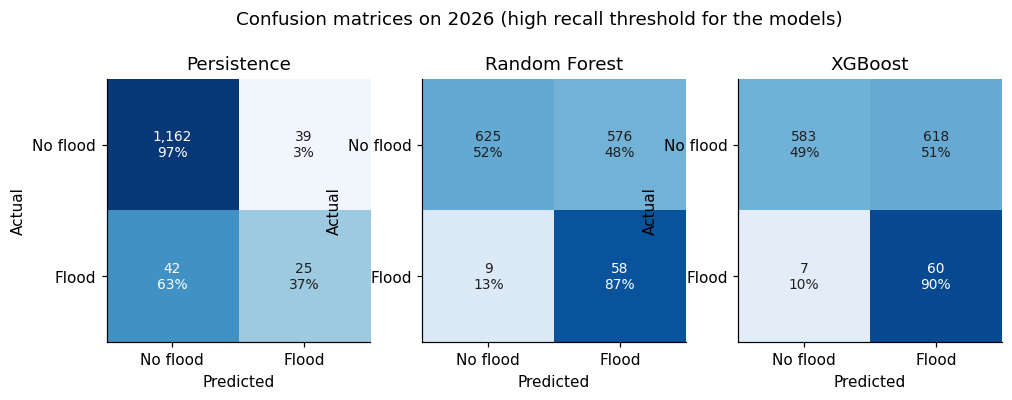

In [16]:
# --- Fig 5: confusion matrices on 2026 (main operating point) ---
mats = {'Persistence': pers_pred,
        'Random Forest': preds[('Random Forest', MAIN_OP)],
        'XGBoost': preds[('XGBoost', MAIN_OP)]}
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, (name, pred) in zip(axes, mats.items()):
    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    share = cm / cm.sum(axis=1, keepdims=True)              # colour by row share (classes are imbalanced)
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}\n{share[i, j]:.0%}', ha='center', va='center', fontsize=9,
                color='white' if share[i, j] > 0.55 else '#1f1f1d')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['No flood', 'Flood'], yticklabels=['No flood', 'Flood'],
           xlabel='Predicted', ylabel='Actual', title=name)
    ax.grid(False)
fig.suptitle(f'Confusion matrices on 2026 ({MAIN_OP.lower()} threshold for the models)', y=1.03)
savefig(fig, 'fig5_confusion_matrices')

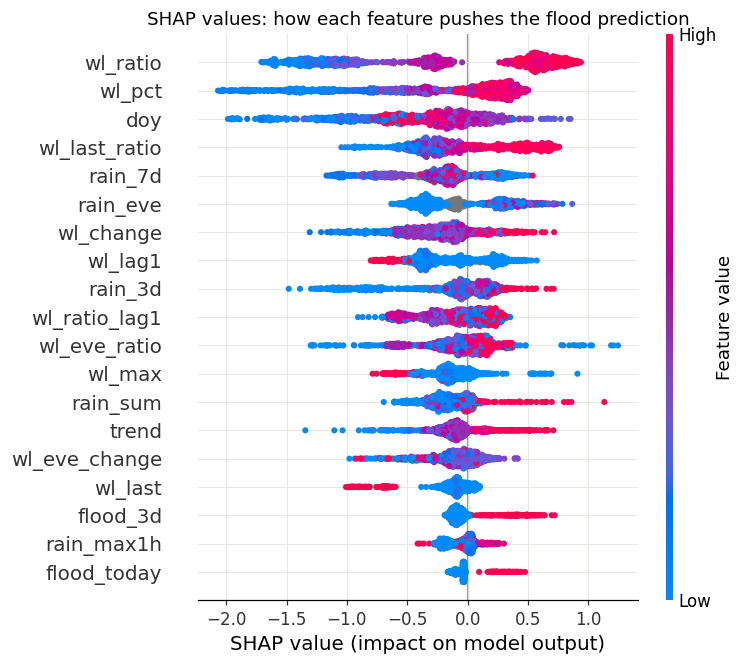

Top features by mean |SHAP|:
wl_ratio         0.759
wl_pct           0.520
doy              0.465
wl_last_ratio    0.339
rain_7d          0.331
rain_eve         0.313
wl_change        0.305
wl_lag1          0.289


In [17]:
# --- Fig 6: SHAP summary for XGBoost (exact tree SHAP values from XGBoost itself) ---
contrib = xgb.get_booster().predict(xgboost.DMatrix(X_te), pred_contribs=True)[:, :-1]
try:
    import shap
    shap.summary_plot(contrib, X_te, max_display=len(FEATURES), show=False, plot_size=(7, 6))
    fig = plt.gcf(); fig.axes[0].set_title('SHAP values: how each feature pushes the flood prediction')
except ImportError:      # fallback: mean absolute SHAP per feature
    imp = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(6, 5.5))
    ax.barh(imp.index, imp.values, color=COLORS['XGBoost'], height=0.6)
    ax.set(xlabel='Mean |SHAP value|', title='XGBoost feature importance (SHAP)')
    ax.grid(axis='y', visible=False)
savefig(fig, 'fig6_shap_summary')

shap_rank = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print('Top features by mean |SHAP|:'); print(shap_rank.head(8).round(3).to_string())

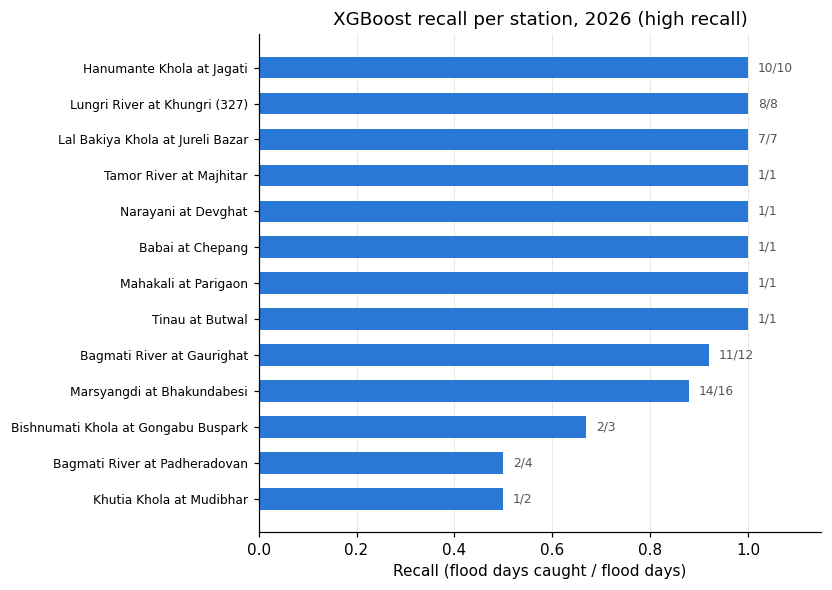

In [18]:
# --- Fig 7: recall per station on 2026 ---
ps = per_station.sort_values(['recall', 'flood_days'])
fig, ax = plt.subplots(figsize=(6.6, 0.36 * len(ps) + 1.2))
ax.barh(ps.station_name, ps.recall, color=COLORS['XGBoost'], height=0.6)
for y, (_, row) in enumerate(ps.iterrows()):
    ax.text(row.recall + 0.02, y, f'{int(row.caught)}/{int(row.flood_days)}', va='center', fontsize=8,
            color='#55544f')
ax.set(xlim=(0, 1.15), xlabel='Recall (flood days caught / flood days)',
       title=f'XGBoost recall per station, 2026 ({MAIN_OP.lower()})')
ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='y', visible=False)
savefig(fig, 'fig7_per_station_recall')

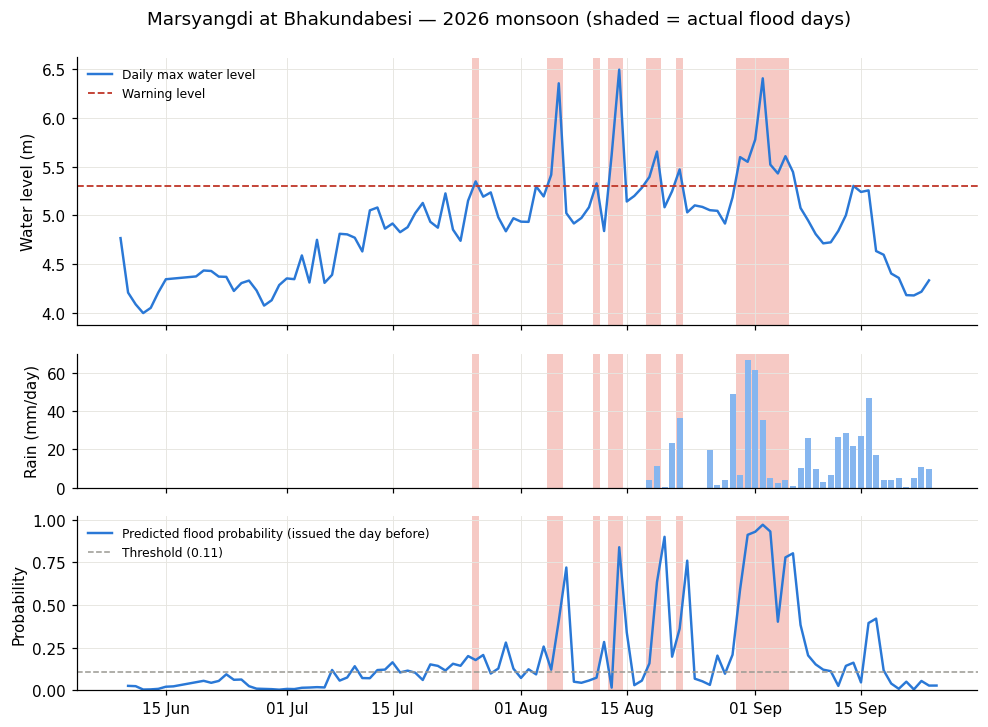

In [19]:
# --- Fig 8: case study — one station through the 2026 monsoon ---
CASE_STATION = None   # e.g. '97'; None = station with the most 2026 flood days
cs = CASE_STATION or test.groupby('station_id')['flood_tomorrow'].sum().idxmax()
s = test[test.station_id == cs].sort_values('date')
prob = pd.Series(test_prob['XGBoost'], index=test.index).loc[s.index]
thr = thresholds[('XGBoost', MAIN_OP)]

fig, axes = plt.subplots(3, 1, figsize=(9, 6.6), sharex=True, gridspec_kw={'height_ratios': [2, 1, 1.3]})
for ax in axes:   # shade the actual flood days
    for d in s.loc[s.flood == 1, 'date']:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=FLOOD_SHADE, lw=0, zorder=0)
axes[0].plot(s.date, s.wl_max, color=COLORS['XGBoost'], lw=1.6, label='Daily max water level')
axes[0].axhline(s.warn.median(), color=WARN_LINE, lw=1.2, ls='--', label='Warning level')
axes[0].set_ylabel('Water level (m)')
axes[0].legend(frameon=False, loc='upper left', fontsize=8)
axes[1].bar(s.date, s.rain_sum, color='#86b6ef', width=0.8)
axes[1].set_ylabel('Rain (mm/day)')
axes[2].plot(s.date + pd.Timedelta(days=1), prob, color=COLORS['XGBoost'], lw=1.6,
             label='Predicted flood probability (issued the day before)')
axes[2].axhline(thr, color=MUTED, lw=1, ls='--', label=f'Threshold ({thr:.2f})')
axes[2].set(ylabel='Probability', ylim=(0, 1.02))
axes[2].legend(frameon=False, loc='upper left', fontsize=8)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle(f'{names.get(cs, cs)} — 2026 monsoon (shaded = actual flood days)', y=0.995)
fig.tight_layout()
savefig(fig, 'fig8_case_study')

10. Summary for the paper

In [20]:
x, rf_, pe = (results.loc[('XGBoost', MAIN_OP)], results.loc[('Random Forest', MAIN_OP)],
              results.loc[('Persistence', '—')])
xm = results.loc[('XGBoost', 'Persistence recall')]
print(f'Stations: {len(selected_ids)} | features: {len(FEATURES)} | XGBoost config: {best_cfg}')
print(split_table.to_string(), '\n')
print(f'XGBoost ({MAIN_OP}):  recall {x.Recall:.2f}, precision {x.Precision:.2f}, F1 {x.F1:.2f}, PR-AUC {x["PR-AUC"]:.2f}')
print(f'Random Forest ({MAIN_OP}): recall {rf_.Recall:.2f}, precision {rf_.Precision:.2f}, F1 {rf_.F1:.2f}, PR-AUC {rf_["PR-AUC"]:.2f}')
print(f'Persistence:          recall {pe.Recall:.2f}, precision {pe.Precision:.2f}, F1 {pe.F1:.2f}')
print(f'At persistence-level recall, XGBoost precision is {xm.Precision:.2f} vs {pe.Precision:.2f} for persistence.')
print(f'{1 - pe.Recall:.0%} of 2026 flood days followed a non-flood day (floods that persistence cannot catch).')
print('Top 5 features (SHAP):', ', '.join(shap_rank.index[:5]))

Stations: 15 | features: 19 | XGBoost config: {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 400}
               rows flood days flood rate
train 2020–24  5290        201      3.80%
val 2025       1414         49      3.47%
test 2026      1268         67      5.28% 

XGBoost (High recall):  recall 0.90, precision 0.09, F1 0.16, PR-AUC 0.17
Random Forest (High recall): recall 0.87, precision 0.09, F1 0.17, PR-AUC 0.18
Persistence:          recall 0.37, precision 0.39, F1 0.38
At persistence-level recall, XGBoost precision is 0.14 vs 0.39 for persistence.
63% of 2026 flood days followed a non-flood day (floods that persistence cannot catch).
Top 5 features (SHAP): wl_ratio, wl_pct, doy, wl_last_ratio, rain_7d


11. Fig. 1 for the paper: how rare floods are, and how many start suddenly

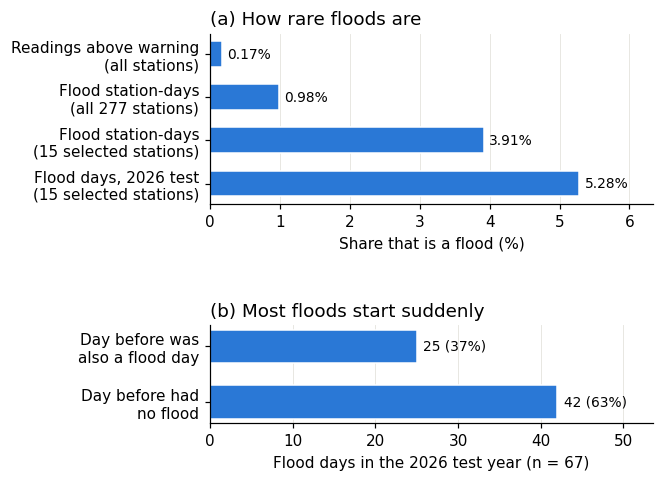

{'Readings above warning (all stations)': 0.17, 'Flood station-days (all 277 stations)': 0.98, 'Flood station-days (15 selected stations)': 3.91, 'Flood days, 2026 test (15 selected stations)': 5.28}
42 of 67 test flood days followed a non-flood day; 25 followed a flood day


In [21]:
# --- Fig. 1 for the paper: how rare floods are, and how many start suddenly ---
# Run this after sections 1-10. It uses tables the notebook has already built.

# (a) share of readings / station-days that are floods
if 'status_counts' in globals():            # available when section 2 read the raw CSV
    sc = pd.concat(status_counts).groupby(level=0).sum()
    above = sc[sc.index.str.contains('ABOVE|DANGER')].sum()
    readings_pct = above / sc.sum() * 100
else:                                       # cached run: numbers printed by section 2 earlier
    readings_pct = (12_265 + 3_457) / (9_088_688 + 12_265 + 3_457) * 100

shares = {
    'Readings above warning\n(all stations)':               readings_pct,
    f'Flood station-days\n(all {river.station_id.nunique()} stations)': river.flood.mean() * 100,
    f'Flood station-days\n({len(selected_ids)} selected stations)':      sel.flood.mean() * 100,
    f'Flood days, {TEST_YEAR} test\n({len(selected_ids)} selected stations)': test.flood_tomorrow.mean() * 100,
}

# (b) test-year flood days: was the day before also a flood day?
floods = test[test.flood_tomorrow == 1]
n_cont  = int((floods.flood_today == 1).sum())
n_onset = int((floods.flood_today == 0).sum())
n_all   = n_cont + n_onset

fig, (a, b) = plt.subplots(2, 1, figsize=(5.2, 4.6),
                           gridspec_kw={'height_ratios': [4, 2.3], 'hspace': 0.9})
labels, vals = list(shares)[::-1], list(shares.values())[::-1]
a.barh(labels, vals, height=0.6, color=COLORS['XGBoost'], edgecolor='white')
for y, v in enumerate(vals):
    a.text(v + 0.08, y, f'{v:.2f}%', va='center', fontsize=9)
a.set(xlim=(0, max(vals) * 1.2), xlabel='Share that is a flood (%)')
a.set_title('(a) How rare floods are', loc='left')
a.grid(axis='y', visible=False)

b.barh(['Day before had\nno flood', 'Day before was\nalso a flood day'], [n_onset, n_cont],
       height=0.6, color=COLORS['XGBoost'], edgecolor='white')
for y, v in enumerate([n_onset, n_cont]):
    b.text(v + 0.8, y, f'{v} ({v / n_all:.0%})', va='center', fontsize=9)
b.set(xlim=(0, n_all * 0.8), xlabel=f'Flood days in the {TEST_YEAR} test year (n = {n_all})')
b.set_title('(b) Most floods start suddenly', loc='left')
b.grid(axis='y', visible=False)

savefig(fig, 'fig_rarity_onset')
print({k.replace(chr(10), ' '): round(float(v), 2) for k, v in shares.items()})
print(f'{n_onset} of {n_all} test flood days followed a non-flood day; {n_cont} followed a flood day')

12. Flood-risk app

In [22]:
# ===================== Flood-risk app (Gradio) =====================
# Uses the model and tables built in sections 1-10, so run the notebook from the top
# (Runtime -> Run all). Gradio is installed in section 1.

import gradio as gr

THRESH = thresholds[('XGBoost', MAIN_OP)]          # high-recall threshold (≈ 0.11)
station_names = station_meta.set_index('station_id')['station_name']
name_to_id = {station_names.get(s, s): s for s in selected_ids}
STATION_CHOICES = sorted(name_to_id)
YEAR_CHOICES = [str(y) for y in sorted(df.year.unique())]
booster = xgb.get_booster()

def rows_for(station, year):
    sid = name_to_id[station]
    return df[(df.station_id == sid) & (df.year == int(year))].sort_values('date')

def date_choices(station, year):
    dates = rows_for(station, year)['date'].dt.strftime('%Y-%m-%d').tolist()
    return gr.Dropdown(choices=dates, value=dates[len(dates) // 2] if dates else None)

def predict(station, year, date):
    if not (station and year and date):
        return 'Choose a station, year and date.', None, None
    s = rows_for(station, year)
    row = s[s.date == pd.Timestamp(date)]
    if row.empty:
        return 'No data for that day.', None, None
    row = row.iloc[[0]]
    p = float(xgb.predict_proba(row[FEATURES])[:, 1][0])
    warn = p >= THRESH
    tomorrow = (pd.Timestamp(date) + pd.Timedelta(days=1)).strftime('%d %b %Y')
    actual = 'FLOOD' if int(row.flood_tomorrow.iloc[0]) == 1 else 'no flood'
    note = '(unseen test year)' if int(year) == TEST_YEAR else (
           '(validation year)' if int(year) == VAL_YEAR else '(training year: the model has seen this data)')

    verdict = (f"## {'⚠️ FLOOD WARNING' if warn else '✅ No warning'} for {tomorrow}\n"
               f"**Predicted flood probability:** {p:.2f} &nbsp;·&nbsp; warning threshold {THRESH:.2f}\n\n"
               f"**What actually happened:** {actual} {note}")

    r = row.iloc[0]
    inputs = pd.DataFrame({
        'Input (on ' + pd.Timestamp(date).strftime('%d %b') + ')': [
            'Max water level (m)', 'Warning level (m)', 'Level ÷ warning level',
            'Last reading of the day (m)', 'Rain today (mm)', 'Rain last 7 days (mm)',
            'Flood today?'],
        'Value': [f"{r.wl_max:.2f}", f"{r.warn:.2f}", f"{r.wl_ratio:.2f}",
                  f"{r.wl_last:.2f}" if pd.notna(r.wl_last) else '—',
                  f"{r.rain_sum:.1f}" if pd.notna(r.rain_sum) else '—',
                  f"{r.rain_7d:.1f}" if pd.notna(r.rain_7d) else '—',
                  'yes' if r.flood_today == 1 else 'no']})

    # Why: the 5 features that pushed this prediction most (SHAP contributions)
    contrib = booster.predict(xgboost.DMatrix(row[FEATURES]), pred_contribs=True)[0, :-1]
    top = pd.Series(contrib, index=FEATURES).sort_values(key=abs, ascending=False).head(5)
    why = pd.DataFrame({'Feature': top.index,
                        'Effect': ['raises risk' if v > 0 else 'lowers risk' for v in top.values],
                        'Strength': top.abs().round(2).values})
    return verdict, inputs, why

def season_plot(station, year, date):
    s = rows_for(station, year)
    if s.empty:
        return None
    prob = xgb.predict_proba(s[FEATURES])[:, 1]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    for ax in (a1, a2):
        for d in s.loc[s.flood == 1, 'date']:
            ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=FLOOD_SHADE, lw=0)
        if date:
            ax.axvline(pd.Timestamp(date) + pd.Timedelta(days=1), color='black', lw=1, ls=':')
    a1.plot(s.date, s.wl_max, color=COLORS['XGBoost'], lw=1.6, label='Daily max water level')
    a1.axhline(s.warn.median(), color=WARN_LINE, ls='--', lw=1.2, label='Warning level')
    a1.set_ylabel('Water level (m)'); a1.legend(frameon=False, loc='upper left', fontsize=8)
    a2.plot(s.date + pd.Timedelta(days=1), prob, color=COLORS['XGBoost'], lw=1.6,
            label='Flood probability (issued the day before)')
    a2.axhline(THRESH, color=MUTED, ls='--', lw=1, label=f'Threshold ({THRESH:.2f})')
    a2.set(ylabel='Probability', ylim=(0, 1.02)); a2.legend(frameon=False, loc='upper left', fontsize=8)
    a2.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    fig.suptitle(f'{station}, {year} monsoon (shaded = actual flood days, dotted = selected day)')
    fig.tight_layout()
    plt.close(fig)
    return fig

with gr.Blocks(title='Nepal next-day flood risk') as app:
    gr.Markdown('# 🌊 Next-day flood risk for Nepal river stations\n'
                'Pick a station and a day. The XGBoost model uses that day\'s river and rain data '
                'to estimate the chance that the river goes **above its warning level tomorrow**.')
    with gr.Row():
        station = gr.Dropdown(STATION_CHOICES, value=STATION_CHOICES[0], label='River station')
        year = gr.Dropdown(YEAR_CHOICES, value=str(TEST_YEAR), label='Monsoon year')
        date = gr.Dropdown([], label='Day the forecast is issued')
    btn = gr.Button('Predict tomorrow', variant='primary')
    verdict = gr.Markdown()
    with gr.Row():
        inputs_tbl = gr.Dataframe(label='What the model saw')
        why_tbl = gr.Dataframe(label='Why: strongest influences (SHAP)')
    plot = gr.Plot(label='Whole monsoon at this station')

    for comp in (station, year):
        comp.change(date_choices, [station, year], date)
    btn.click(predict, [station, year, date], [verdict, inputs_tbl, why_tbl])
    btn.click(season_plot, [station, year, date], plot)
    app.load(date_choices, [station, year], date)

app.launch(share=True, debug=False)   # share=True gives a public link for ~72 hours

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cecab0ebc9f1451c27.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
